# Flood Risk Prediction — Public Tool (XGBoost)

Two-mode Gradio app powered by a **XGBoost classifier**, trained on 15 features: the mentor's original 7 (Task 5) + 5 Land Use/Land Cover columns + Antecedent Rainfall, Temperature, and Soil Wetness.
- **Casual Mode**: District, Month, Year, expected Rainfall — everything else (elevation, coordinates, discharge, LULC, antecedent rainfall, temperature, soil wetness) is looked up automatically.
- **Advanced Mode**: choose between (A) District + Station with editable Rainfall/Discharge/Month/Year/Temperature/Soil Wetness, or (B) raw Latitude/Longitude (with live elevation lookup) + manual Rainfall/Discharge/Month/Year/Temperature/Soil Wetness.

## Step 1: Install packages

In [1]:
!pip install gradio scikit-learn xgboost requests -q

## Step 2: Upload your dataset
Select `india_5state_flood_dataset_2021_2025.csv`.

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## Step 3: Load data and train the XGBoost model

In [3]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix

MODEL_NAME = "XGBoost"

df = pd.read_csv("/content/drive/MyDrive/india_5state_flood_dataset_2021_2025.csv")

# --- Light cleanup of display-only columns (River/Basin are not model features) ---
df['River'] = df['River'].astype(str).str.strip().replace('-', 'Unrecorded river')
df['Basin'] = df['Basin'].astype(str).str.strip()

le = LabelEncoder()
df['target'] = le.fit_transform(df['Flood_Risk_Level'])

FEATURES = ['Rainfall_mm_day', 'Elevation_m', 'Latitude', 'Longitude', 'Discharge_max_m3s', 'Month', 'Year','Pct_Cropland', 'Pct_Urban_BuiltUp', 'Pct_Forest_Total', 'Pct_Herbaceous_wetland', 'Pct_Water_Permanent','Antecedent_Rainfall_2mo', 'Temperature_C', 'Soil_Wetness']
X = df[FEATURES]
y = df['target']

# 80/20 train-test split per guidelines (Task 6)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

eval_set = [(X_train, y_train), (X_test, y_test)]

model = XGBClassifier(
    n_estimators=200, max_depth=6, learning_rate=0.1,
    random_state=42, eval_metric=['mlogloss', 'merror']  # merror = 1 - accuracy
)
model.fit(X_train, y_train, eval_set=eval_set, verbose=False)

results = model.evals_result()

# ---- Evaluation on the held-out test set (Task 8) ----
y_pred = model.predict(X_test)
acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred, average='weighted', zero_division=0)
rec = recall_score(y_test, y_pred, average='weighted', zero_division=0)
f1 = f1_score(y_test, y_pred, average='weighted', zero_division=0)

print(f"=== {MODEL_NAME} (15 features) — Test Set Performance ===")
print(f"Accuracy:  {acc:.3f}")
print(f"Precision: {prec:.3f}")
print(f"Recall:    {rec:.3f}")
print(f"F1-Score:  {f1:.3f}")

print("\nConfusion Matrix (rows=actual, cols=predicted):")
print(pd.DataFrame(confusion_matrix(y_test, y_pred), index=le.classes_, columns=le.classes_))

print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=le.classes_, zero_division=0))

print("Feature importances:")
for feat, imp in sorted(zip(FEATURES, model.feature_importances_), key=lambda x: -x[1]):
    print(f"  {feat}: {imp:.3f}")


=== XGBoost (15 features) — Test Set Performance ===
Accuracy:  0.887
Precision: 0.886
Recall:    0.887
F1-Score:  0.886

Confusion Matrix (rows=actual, cols=predicted):
        High   Low  Medium
High     179     2      76
Low        1  1519      57
Medium    45    78     336

Classification Report:
              precision    recall  f1-score   support

        High       0.80      0.70      0.74       257
         Low       0.95      0.96      0.96      1577
      Medium       0.72      0.73      0.72       459

    accuracy                           0.89      2293
   macro avg       0.82      0.80      0.81      2293
weighted avg       0.89      0.89      0.89      2293

Feature importances:
  Discharge_max_m3s: 0.201
  Rainfall_mm_day: 0.107
  Soil_Wetness: 0.093
  Month: 0.083
  Longitude: 0.058
  Pct_Forest_Total: 0.056
  Pct_Cropland: 0.054
  Pct_Herbaceous_wetland: 0.051
  Latitude: 0.051
  Elevation_m: 0.047
  Temperature_C: 0.045
  Pct_Water_Permanent: 0.042
  Pct_Urban_Built

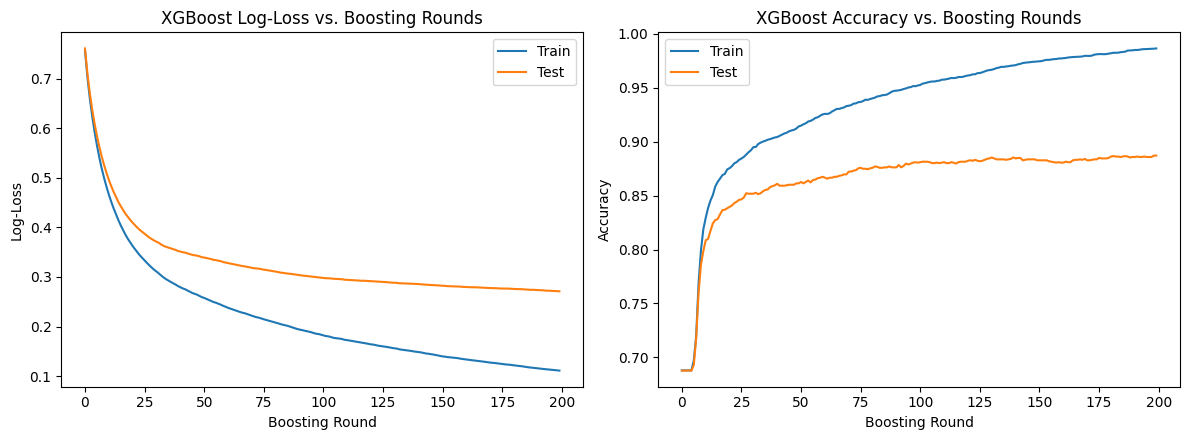

In [4]:
import matplotlib.pyplot as plt

epochs = len(results['validation_0']['mlogloss'])
x_axis = range(epochs)

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))

# Loss curve
ax[0].plot(x_axis, results['validation_0']['mlogloss'], label='Train')
ax[0].plot(x_axis, results['validation_1']['mlogloss'], label='Test')
ax[0].set_title('XGBoost Log-Loss vs. Boosting Rounds')
ax[0].set_xlabel('Boosting Round'); ax[0].set_ylabel('Log-Loss'); ax[0].legend()

# Accuracy curve (1 - error)
train_acc = [1 - e for e in results['validation_0']['merror']]
test_acc  = [1 - e for e in results['validation_1']['merror']]
ax[1].plot(x_axis, train_acc, label='Train')
ax[1].plot(x_axis, test_acc, label='Test')
ax[1].set_title('XGBoost Accuracy vs. Boosting Rounds')
ax[1].set_xlabel('Boosting Round'); ax[1].set_ylabel('Accuracy'); ax[1].legend()

plt.tight_layout()
plt.savefig('accuracy_loss_curves.png', dpi=200)
plt.show()

## Step 4: Precompute lookup tables (district & station averages)

In [5]:
LULC_FEATURES = ['Pct_Cropland', 'Pct_Urban_BuiltUp', 'Pct_Forest_Total', 'Pct_Herbaceous_wetland', 'Pct_Water_Permanent']

def _mode_or_default(series, default):
    m = series.mode()
    return m.iat[0] if not m.empty else default

# Global medians — used as sensible default values for manual inputs, and as a last-resort
# fallback when a district/month combination has no historical rows to average.
GLOBAL_ANTECEDENT_MEDIAN = round(df['Antecedent_Rainfall_2mo'].median(), 2)
GLOBAL_TEMPERATURE_MEDIAN = round(df['Temperature_C'].median(), 2)
GLOBAL_SOIL_WETNESS_MEDIAN = round(df['Soil_Wetness'].median(), 3)

# District-level averages: elevation, coordinates, LULC (static per district) — used for Casual Mode auto-fill
district_agg = {'Elevation_m': 'mean', 'Latitude': 'mean', 'Longitude': 'mean'}
district_agg.update({col: 'mean' for col in LULC_FEATURES})
district_info = df.groupby('District').agg(district_agg).round(4)

# Most common River/Basin per district — a district can have multiple stations/rivers,
# so this is a representative (not exact) label, used only in Casual Mode's info note.
district_primary_river = df.groupby('District')['River'].agg(lambda s: _mode_or_default(s, 'Unrecorded river'))
district_primary_basin = df.groupby('District')['Basin'].agg(lambda s: _mode_or_default(s, 'Unknown basin'))

# District + Month historical averages — Casual Mode default for ALL of: discharge,
# antecedent rainfall, temperature, and soil wetness (Casual Mode never asks about these).
district_month_discharge = df.groupby(['District','Month'])['Discharge_max_m3s'].mean().round(2)
district_month_antecedent = df.groupby(['District','Month'])['Antecedent_Rainfall_2mo'].mean().round(2)
district_month_temperature = df.groupby(['District','Month'])['Temperature_C'].mean().round(2)
district_month_soil = df.groupby(['District','Month'])['Soil_Wetness'].mean().round(3)

# Station-level info: coordinates, river, basin, elevation, and LULC (inherited from its district)
station_agg = {'Latitude':'first', 'Longitude':'first', 'River':'first', 'Basin':'first', 'Elevation_m':'first'}
station_agg.update({col: 'first' for col in LULC_FEATURES})
station_info = df.groupby(['District','Station']).agg(station_agg).reset_index()
station_month_discharge = df.groupby(['Station','Month'])['Discharge_max_m3s'].mean().round(2)
station_month_antecedent = df.groupby(['Station','Month'])['Antecedent_Rainfall_2mo'].mean().round(2)

districts_list = sorted(df['District'].unique().tolist())
district_stations_map = df.groupby('District')['Station'].unique().apply(sorted).to_dict()

# State-level mapping (used for the State dropdown in Casual Mode and Advanced -> District & Station)
states_list = sorted(df['State'].unique().tolist())
state_districts_map = df.groupby('State')['District'].unique().apply(sorted).to_dict()

# For Advanced -> Lat/Lon mode: nearest-station lookup so LULC/River/Basin/Antecedent-rainfall
# can still be auto-filled even when the user enters raw coordinates instead of picking a district.
_station_coords = station_info[['Latitude', 'Longitude']].to_numpy()

def nearest_station_row(lat, lon):
    dists = np.sqrt((_station_coords[:, 0] - lat) ** 2 + (_station_coords[:, 1] - lon) ** 2)
    nearest_idx = int(np.argmin(dists))
    return station_info.iloc[nearest_idx]

print(f"{len(states_list)} states, {len(districts_list)} districts, {df['Station'].nunique()} stations available.")


5 states, 98 districts, 242 stations available.


## Step 5: Live elevation lookup (for Advanced Mode's Lat/Lon path)
Uses the free Open-Topo-Data API (SRTM 30m) — needs internet access, which Colab has.

In [6]:
import requests

def fetch_elevation(lat, lon):
    try:
        url = f"https://api.opentopodata.org/v1/srtm30m?locations={lat},{lon}"
        resp = requests.get(url, timeout=10)
        resp.raise_for_status()
        data = resp.json()
        return data['results'][0]['elevation']
    except Exception as e:
        print(f"Elevation lookup failed: {e}")
        return None  # caller should handle None (e.g., ask user to enter manually)


## Step 6: Prediction function (shared by both modes)

In [7]:
def predict_risk(rainfall, elevation, latitude, longitude, discharge, month, year,
                  antecedent_rainfall, temperature, soil_wetness, lulc):
    """Returns (predicted_label, formatted_probability_text)."""
    sample = pd.DataFrame([{
        'Rainfall_mm_day': rainfall,
        'Elevation_m': elevation,
        'Latitude': latitude,
        'Longitude': longitude,
        'Discharge_max_m3s': discharge,
        'Month': month,
        'Year': year,
        'Antecedent_Rainfall_2mo': antecedent_rainfall,
        'Temperature_C': temperature,
        'Soil_Wetness': soil_wetness,
        **lulc
    }])[FEATURES]
    pred_encoded = model.predict(sample)[0]
    pred_label = le.inverse_transform([pred_encoded])[0]
    proba = model.predict_proba(sample)[0]
    proba_text = ", ".join([f"{cls}: {p:.1%}" for cls, p in zip(le.classes_, proba)])
    return pred_label, proba_text


## Step 7: Build the two-mode Gradio app (Model: XGBoost)

In [8]:
import gradio as gr

# ---------- Result card styling ----------
RISK_COLORS = {"Low": "#16a34a", "Medium": "#d97706", "High": "#dc2626"}
RISK_BG     = {"Low": "#f0fdf4", "Medium": "#fffbeb", "High": "#fef2f2"}
RISK_ICON   = {"Low": "\U0001F7E2", "Medium": "\U0001F7E0", "High": "\U0001F534"}

def result_card(label, proba_text):
    color = RISK_COLORS.get(label, "#374151")
    bg = RISK_BG.get(label, "#f9fafb")
    icon = RISK_ICON.get(label, "\u26AA")
    return f"""
<div style="border:1px solid {color}33; border-left:6px solid {color}; background:{bg} !important;
            border-radius:12px; padding:18px 22px; font-family:inherit;">
  <div style="font-size:22px; font-weight:700; color:{color}; margin-bottom:6px;">
    {icon} {label} Flood Risk
  </div>
  <div style="font-size:13.5px; color:#4b5563 !important;">{proba_text}</div>
</div>
"""

def info_card(lines):
    body = "".join(f'<div style="margin:3px 0;">\u2022 {l}</div>' for l in lines)
    return f"""
<div style="background:#f8fafc !important; border:1px solid #e2e8f0; border-radius:12px;
            padding:14px 18px; font-size:13px; color:#334155; !important;">
  {body}
</div>
"""

def error_card(message):
    return f"""
<div style="border:1px solid #dc262633; border-left:6px solid #dc2626; background:#fef2f2;
            border-radius:12px; padding:16px 20px; color:#991b1b; font-size:14px;">
  \u26A0\uFE0F {message}
</div>
"""

# ---------- CASUAL MODE ----------
def casual_predict(state, district, month, year, rainfall):
    elevation = district_info.loc[district, 'Elevation_m']
    lat = district_info.loc[district, 'Latitude']
    lon = district_info.loc[district, 'Longitude']
    discharge = district_month_discharge.get((district, month), df['Discharge_max_m3s'].median())
    antecedent = district_month_antecedent.get((district, month), GLOBAL_ANTECEDENT_MEDIAN)
    temperature = district_month_temperature.get((district, month), GLOBAL_TEMPERATURE_MEDIAN)
    soil_wetness = district_month_soil.get((district, month), GLOBAL_SOIL_WETNESS_MEDIAN)
    lulc = district_info.loc[district, LULC_FEATURES].to_dict()
    river = district_primary_river.get(district, 'Unrecorded river')
    basin = district_primary_basin.get(district, 'Unknown basin')

    label, proba_text = predict_risk(rainfall, elevation, lat, lon, discharge, month, year,
                                      antecedent, temperature, soil_wetness, lulc)
    details = [
        f"Elevation: <b>{elevation:.0f} m</b>",
        f"Typical river discharge for {district} in month {month}: <b>{discharge:.1f} m³/s</b>",
        f"Auto-filled: antecedent rainfall <b>{antecedent:.1f} mm</b>, temperature <b>{temperature:.1f}°C</b>, soil wetness <b>{soil_wetness:.2f}</b>",
        f"Primary river (representative): <b>{river}</b>",
        f"Basin: <b>{basin}</b>",
    ]
    return result_card(label, proba_text), info_card(details)

def update_casual_district_dropdown(state):
    dists = state_districts_map.get(state, [])
    return gr.update(choices=dists, value=dists[0] if dists else None)

# ---------- ADVANCED MODE: Path A (District + Station) ----------
def advanced_district_predict(state, district, station, month, year, rainfall, discharge_override, use_override,
                                temperature, soil_wetness, antecedent_override, use_antecedent_override):
    row = station_info[(station_info['District']==district) & (station_info['Station']==station)].iloc[0]
    elevation = row['Elevation_m']
    lat = row['Latitude']
    lon = row['Longitude']
    lulc = row[LULC_FEATURES].to_dict()

    if use_antecedent_override:
        antecedent = antecedent_override
    else:
        antecedent = station_month_antecedent.get((station, month),
                      district_month_antecedent.get((district, month), GLOBAL_ANTECEDENT_MEDIAN))

    if use_override:
        discharge = discharge_override
    else:
        discharge = station_month_discharge.get((station, month),
                     district_month_discharge.get((district, month), df['Discharge_max_m3s'].median()))

    label, proba_text = predict_risk(rainfall, elevation, lat, lon, discharge, month, year,
                                      antecedent, temperature, soil_wetness, lulc)
    antecedent_source = "your reading" if use_antecedent_override else "historical seasonal average"
    details = [
        f"Station: <b>{station}</b>",
        f"River: <b>{row['River']}</b> &nbsp;|&nbsp; Basin: <b>{row['Basin']}</b>",
        f"Discharge used: <b>{discharge:.1f} m³/s</b>",
        f"Antecedent rainfall used: <b>{antecedent:.1f} mm</b> ({antecedent_source})",
    ]
    return result_card(label, proba_text), info_card(details)

def update_district_dropdown(district):
    stations = district_stations_map.get(district, [])
    return gr.update(choices=stations, value=stations[0] if len(stations) else None)

def update_state_dropdown(state):
    dists = state_districts_map.get(state, [])
    first_district = dists[0] if dists else None
    stations = district_stations_map.get(first_district, [])
    return (gr.update(choices=dists, value=first_district),
            gr.update(choices=stations, value=stations[0] if stations else None))

# ---------- ADVANCED MODE: Path B (Lat/Lon manual) ----------
def advanced_latlon_predict(latitude, longitude, month, year, rainfall, discharge, temperature, soil_wetness,
                              antecedent_override, use_antecedent_override):
    elevation = fetch_elevation(latitude, longitude)
    if elevation is None:
        return error_card("Could not determine elevation for these coordinates. Please try again or switch to the District & Station path."), ""
    nearest = nearest_station_row(latitude, longitude)
    lulc = nearest[LULC_FEATURES].to_dict()
    if use_antecedent_override:
        antecedent = antecedent_override
    else:
        antecedent = district_month_antecedent.get((nearest['District'], month), GLOBAL_ANTECEDENT_MEDIAN)
    label, proba_text = predict_risk(rainfall, elevation, latitude, longitude, discharge, month, year,
                                      antecedent, temperature, soil_wetness, lulc)
    antecedent_source = "your reading" if use_antecedent_override else "historical seasonal average"
    details = [
        f"Elevation at ({latitude}, {longitude}): <b>{elevation:.0f} m</b>",
        f"Nearest reference station: <b>{nearest['Station']}</b> ({nearest['District']})",
        f"River: <b>{nearest['River']}</b> &nbsp;|&nbsp; Basin: <b>{nearest['Basin']}</b>",
        f"Antecedent rainfall used: <b>{antecedent:.1f} mm</b> ({antecedent_source})",
    ]
    return result_card(label, proba_text), info_card(details)


# ---------- Styling ----------
CUSTOM_CSS = """
@import url('https://fonts.googleapis.com/css2?family=Inter:wght@400;500;600;700&display=swap');
* { font-family: 'Inter', sans-serif !important; }

.app-header {
    background: linear-gradient(135deg, #0ea5e9 0%, #2563eb 60%, #1d4ed8 100%);
    border-radius: 16px;
    padding: 28px 32px;
    margin-bottom: 18px;
    color: white !important;
}
.app-header h1 { margin: 0 0 6px 0; font-size: 26px; font-weight: 700; color: white !important; }
.app-header p { margin: 0; opacity: 0.92; font-size: 14.5px; color: white !important; }

.panel {
    background: #ffffff !important;
    border: 1px solid #e5e7eb;
    border-radius: 14px;
    padding: 18px 20px 6px 20px;
}
/* Force result/info card text + background to always render regardless of theme/dark mode */
.panel div, .panel span {
    color: inherit;
}

.section-label {
    font-weight: 600;
    font-size: 14px;
    color: #1e3a8a !important;
    margin: 4px 0 10px 0;
    letter-spacing: 0.2px;
}
.gr-button-primary {
    background: linear-gradient(135deg, #2563eb, #1d4ed8) !important;
    border: none !important;
}

/* --- Fix 2: strip the default grey background/border that gr.Group() adds,
   so Advanced Mode's groups look identical to Casual Mode --- */
.panel-group, .panel-group > .form, .panel-group.gr-group {
    background: transparent !important;
    border: none !important;
    box-shadow: none !important;
    padding: 0 !important;
}

/* --- Fix 3: make the slider track visible in both light/dark, only the thumb was showing --- */
input[type="range"] {
    -webkit-appearance: none;
    appearance: none;
    height: 6px;
    border-radius: 999px;
    background: #cbd5e1 !important;   /* visible light-grey track */
}
input[type="range"]::-webkit-slider-runnable-track {
    height: 6px;
    border-radius: 999px;
    background: #cbd5e1 !important;
}
input[type="range"]::-webkit-slider-thumb {
    -webkit-appearance: none;
    width: 16px;
    height: 16px;
    border-radius: 50%;
    background: #2563eb !important;
    border: 2px solid white;
    margin-top: -5px;
    cursor: pointer;
}
input[type="range"]::-moz-range-track {
    height: 6px;
    border-radius: 999px;
    background: #cbd5e1 !important;
}
input[type="range"]::-moz-range-thumb {
    width: 16px;
    height: 16px;
    border-radius: 50%;
    background: #2563eb !important;
    border: 2px solid white;
    cursor: pointer;
}
"""

with gr.Blocks(title="Flood Risk Prediction Tool", theme=gr.themes.Soft(primary_hue="blue", neutral_hue="slate"), css=CUSTOM_CSS) as demo:
    gr.HTML(f"""
    <div class="app-header">
      <h1>\U0001F30A Flood Risk Prediction Tool</h1>
      <p>Model used: <b>{MODEL_NAME}</b> — trained on 5 years of rainfall, discharge, terrain, land-use, antecedent rainfall, temperature, and soil wetness data across 5 Indian states.</p>
    </div>
    """)

    with gr.Tabs():
        # ---------------- CASUAL TAB ----------------
        with gr.Tab("\U0001F9ED Casual Mode"):
            gr.Markdown("Quick check — pick your state, district, the month, and expected rainfall. Everything else (including temperature and soil wetness) is filled in automatically.")
            with gr.Row():
                with gr.Column(scale=1, elem_classes="panel"):
                    gr.Markdown('<div class="section-label">INPUTS</div>')
                    c_state = gr.Dropdown(choices=states_list, value=states_list[0], label="State")
                    c_district = gr.Dropdown(choices=state_districts_map[states_list[0]],
                                              value=state_districts_map[states_list[0]][0], label="District")
                    c_month = gr.Slider(1, 12, value=7, step=1, label="Month (1=Jan, 12=Dec)")
                    c_year = gr.Number(value=2025, label="Year")
                    c_rainfall = gr.Number(value=15.0, label="Expected Rainfall (mm/day)")
                    c_btn = gr.Button("Predict Flood Risk", variant="primary")
                with gr.Column(scale=1, elem_classes="panel"):
                    gr.Markdown('<div class="section-label">RESULT</div>')
                    c_result = gr.HTML()
                    c_note = gr.HTML()

            c_state.change(update_casual_district_dropdown, inputs=c_state, outputs=c_district)
            c_btn.click(casual_predict, inputs=[c_state, c_district, c_month, c_year, c_rainfall],
                        outputs=[c_result, c_note])

        # ---------------- ADVANCED TAB ----------------
        with gr.Tab("\u2699\uFE0F Advanced Mode"):
            gr.Markdown("More control — choose State, District & Station, or enter raw coordinates directly. Temperature and Soil Wetness are entered manually in both paths below, and you can optionally override Discharge and Antecedent Rainfall with your own real readings instead of historical averages.")
            input_method = gr.Radio(choices=["District & Station", "Latitude / Longitude"],
                                     value="District & Station", label="Input Method")

            # --- Path A: District & Station ---
            with gr.Group(visible=True, elem_classes="panel-group") as path_a_group:
                with gr.Row():
                    with gr.Column(scale=1, elem_classes="panel"):
                        gr.Markdown('<div class="section-label">INPUTS</div>')
                        a_state = gr.Dropdown(choices=states_list, value=states_list[0], label="State")
                        a_district = gr.Dropdown(choices=state_districts_map[states_list[0]],
                                                  value=state_districts_map[states_list[0]][0], label="District")
                        a_station = gr.Dropdown(choices=district_stations_map[state_districts_map[states_list[0]][0]],
                                                 value=district_stations_map[state_districts_map[states_list[0]][0]][0],
                                                 label="Station")
                        a_month = gr.Slider(1, 12, value=7, step=1, label="Month")
                        a_year = gr.Number(value=2025, label="Year")
                        a_rainfall = gr.Number(value=15.0, label="Rainfall (mm/day)")
                        a_use_override = gr.Checkbox(value=False, label="I have real river discharge data")
                        a_discharge = gr.Number(value=0.0, label="River Discharge (m3/s) — only used if checkbox above is ticked")
                        a_temperature = gr.Number(value=GLOBAL_TEMPERATURE_MEDIAN, label="Temperature (°C)")
                        a_soil = gr.Number(value=GLOBAL_SOIL_WETNESS_MEDIAN, label="Soil Wetness (0-1 fraction, higher = wetter)")
                        a_use_ante_override = gr.Checkbox(value=False, label="I have a real 2-month antecedent rainfall reading")
                        a_antecedent = gr.Number(value=GLOBAL_ANTECEDENT_MEDIAN, label="Antecedent Rainfall, last 2 months (mm) — only used if checkbox above is ticked. Providing your real reading instead of the seasonal average gives a more accurate prediction, especially in an unusually wet or dry stretch.")
                        a_btn = gr.Button("Predict Flood Risk", variant="primary")
                    with gr.Column(scale=1, elem_classes="panel"):
                        gr.Markdown('<div class="section-label">RESULT</div>')
                        a_result = gr.HTML()
                        a_note = gr.HTML()

                a_state.change(update_state_dropdown, inputs=a_state, outputs=[a_district, a_station])
                a_district.change(update_district_dropdown, inputs=a_district, outputs=a_station)
                a_btn.click(advanced_district_predict,
                            inputs=[a_state, a_district, a_station, a_month, a_year, a_rainfall, a_discharge, a_use_override,
                                    a_temperature, a_soil, a_antecedent, a_use_ante_override],
                            outputs=[a_result, a_note])

            # --- Path B: Latitude / Longitude ---
            with gr.Group(visible=False, elem_classes="panel-group") as path_b_group:
                with gr.Row():
                    with gr.Column(scale=1, elem_classes="panel"):
                        gr.Markdown('<div class="section-label">INPUTS</div>')
                        b_lat = gr.Number(value=10.0, label="Latitude")
                        b_lon = gr.Number(value=76.0, label="Longitude")
                        b_month = gr.Slider(1, 12, value=7, step=1, label="Month")
                        b_year = gr.Number(value=2025, label="Year")
                        b_rainfall = gr.Number(value=15.0, label="Rainfall (mm/day)")
                        b_discharge = gr.Number(value=50.0, label="River Discharge (m3/s)")
                        b_temperature = gr.Number(value=GLOBAL_TEMPERATURE_MEDIAN, label="Temperature (°C)")
                        b_soil = gr.Number(value=GLOBAL_SOIL_WETNESS_MEDIAN, label="Soil Wetness (0-1 fraction, higher = wetter)")
                        b_use_ante_override = gr.Checkbox(value=False, label="I have a real 2-month antecedent rainfall reading")
                        b_antecedent = gr.Number(value=GLOBAL_ANTECEDENT_MEDIAN, label="Antecedent Rainfall, last 2 months (mm) — only used if checkbox above is ticked. Providing your real reading instead of the seasonal average gives a more accurate prediction, especially in an unusually wet or dry stretch.")
                        b_btn = gr.Button("Predict Flood Risk", variant="primary")
                    with gr.Column(scale=1, elem_classes="panel"):
                        gr.Markdown('<div class="section-label">RESULT</div>')
                        b_result = gr.HTML()
                        b_note = gr.HTML()

                b_btn.click(advanced_latlon_predict,
                            inputs=[b_lat, b_lon, b_month, b_year, b_rainfall, b_discharge, b_temperature, b_soil,
                                    b_antecedent, b_use_ante_override],
                            outputs=[b_result, b_note])

            def toggle_path(method):
                return gr.update(visible=(method=="District & Station")), gr.update(visible=(method=="Latitude / Longitude"))

            input_method.change(toggle_path, inputs=input_method, outputs=[path_a_group, path_b_group])

demo.launch(share=True,footer_links=[])


/tmp/ipykernel_1412/2207918333.py:219: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme, css. Please pass these parameters to launch() instead.
  with gr.Blocks(title="Flood Risk Prediction Tool", theme=gr.themes.Soft(primary_hue="blue", neutral_hue="slate"), css=CUSTOM_CSS) as demo:


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://375a2ea4640798b0c2.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


## Notes
- **Model used: XGBoost** — see the printed metrics in Step 3 for its accuracy/precision/recall/F1 on this dataset.
- **Casual Mode** never asks about discharge, elevation, temperature, soil wetness, or antecedent rainfall — all are silently filled from historical district averages.
- **Advanced Mode → District & Station**: discharge and antecedent rainfall each default to historical averages for that station/district and month, unless you tick their respective checkboxes and enter your own real reading. Temperature and Soil Wetness are always entered manually (pre-filled with the dataset median as a starting point).
- **Advanced Mode → Latitude/Longitude**: elevation is fetched live for your coordinates. Temperature and Soil Wetness are entered manually here too, and antecedent rainfall can optionally be overridden the same way.
- **Why override the historical averages?** A district-and-month average is only a typical value for that time of year — during an unusually wet or dry stretch (exactly when flood risk is most in question), the real recent reading can differ from it substantially. Entering your own discharge or antecedent-rainfall figure, when you have one, gives the model more accurate, up-to-date information and a more trustworthy prediction than falling back on a seasonal average.
- `share=True` gives a public link valid ~72 hours — good for demos and mentor review.